In [ ]:
# ===== Cell 1: Libraries and setup =====
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, models, transforms

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Fix random seeds so results are reproducible for anyone who runs this notebook
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if Colab gave us one, otherwise fall back to CPU (much slower)
device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


100%|██████████| 94.3M/94.3M [00:00<00:00, 331MB/s]


Original EuroSAT classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Total images: 27000

Our classes: ['field', 'vegetation', 'building', 'road']
Train tiles: 6400 | Validation tiles: 1600


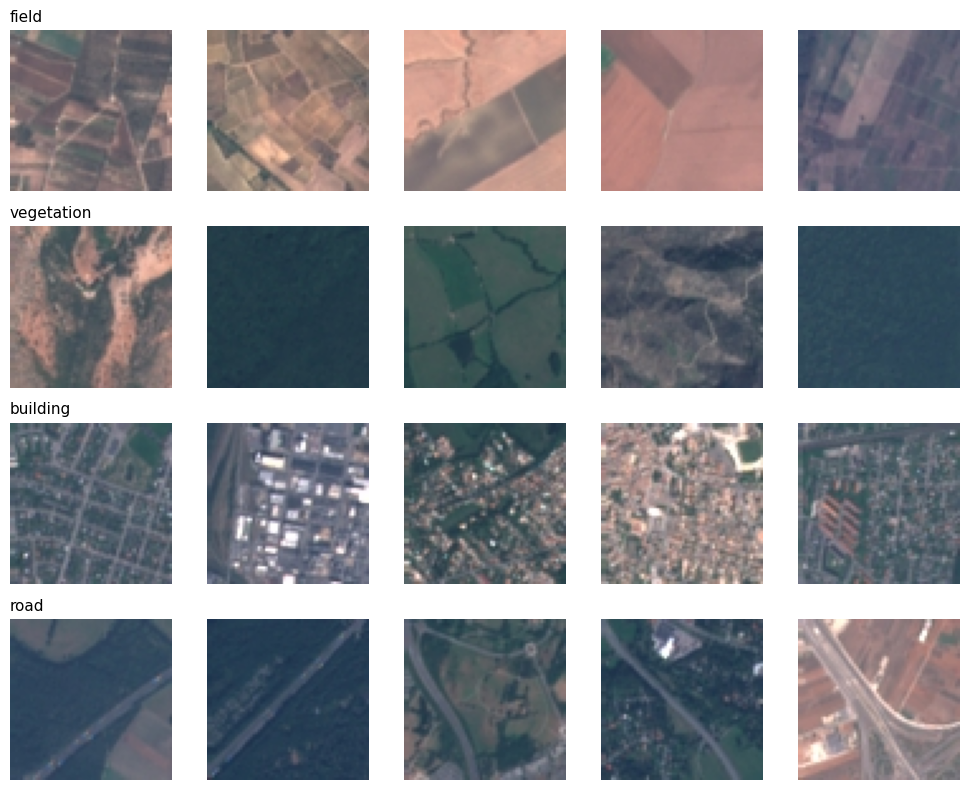

In [ ]:
# ===== Cell 2: Download EuroSAT, group classes, split train/validation =====

# 1) Download EuroSAT (~90 MB, 27,000 satellite tiles, 64x64 px, 10 classes).
#    No transform yet: we get raw PIL images and add transforms in the next cell.
DATA_DIR = "./data"
full = datasets.EuroSAT(root=DATA_DIR, download=True)
print("Original EuroSAT classes:", full.classes)
print("Total images:", len(full))

# 2) Group the original classes into the 4 that match what the CanSat camera sees.
#    (Bare land, sky and tents don't exist in EuroSAT; we add them later in Part B.)
GROUPS = {
    "field":      ["AnnualCrop", "PermanentCrop"],
    "vegetation": ["Pasture", "HerbaceousVegetation", "Forest"],
    "building":   ["Residential",  "Industrial"],
    "road":       ["Highway"],
}
class_names = list(GROUPS.keys())

# Map the original class index -> our new class index
orig_to_new = {}
for new_idx, (group, originals) in enumerate(GROUPS.items()):
    for name in originals:
        orig_to_new[full.class_to_idx[name]] = new_idx

# 3) Collect (image_index, new_label) pairs for each of our classes
per_class = {i: [] for i in range(len(class_names))}
for img_idx, orig_label in enumerate(full.targets):
    if orig_label in orig_to_new:
        per_class[orig_to_new[orig_label]].append(img_idx)

# 4) Keep at most 2000 tiles per class (balanced + fast), then split 80% / 20%
MAX_PER_CLASS = 2000
train_items, val_items = [], []
for label, idxs in per_class.items():
    random.shuffle(idxs)
    idxs = idxs[:MAX_PER_CLASS]
    split = int(0.8 * len(idxs))
    train_items += [(i, label) for i in idxs[:split]]
    val_items   += [(i, label) for i in idxs[split:]]

random.shuffle(train_items)
print(f"\nOur classes: {class_names}")
print(f"Train tiles: {len(train_items)} | Validation tiles: {len(val_items)}")

# 5) Quick look: 5 random examples of each class
fig, axes = plt.subplots(len(class_names), 5, figsize=(10, 8))
for row, label in enumerate(range(len(class_names))):
    examples = random.sample([i for i, l in train_items if l == label], 5)
    for col, img_idx in enumerate(examples):
        axes[row, col].imshow(full[img_idx][0])
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(class_names[label], loc="left", fontsize=11)
plt.tight_layout()
plt.show()

Batches per epoch (train): 100
Batches per epoch (val):   25


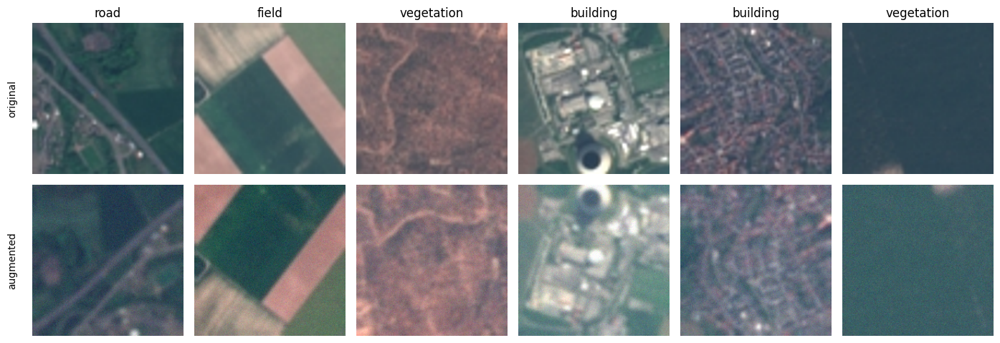

In [ ]:
# ===== Cell 3: Transforms and data loaders =====

IMG_SIZE = 224  # MobileNetV3 was pretrained on 224x224 images

# ImageNet statistics: the pretrained model expects inputs normalized like this
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# --- Custom transform: add random Gaussian noise (mimics a cheap camera sensor) ---
class AddGaussianNoise:
    def __init__(self, std=0.03):
        self.std = std
    def __call__(self, tensor):
        noisy = tensor + torch.randn_like(tensor) * self.std
        return noisy.clamp(0, 1)

# --- Training transforms: augmentation + "make it look like ESP32-CAM" ---
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    # Rotate by a random multiple of 90 degrees (no black corners on square images)
    transforms.Lambda(lambda im: im.rotate(random.choice([0, 90, 180, 270]))),
    # Random brightness / contrast / color changes (different light, different camera)
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    # Blur half of the images (the CanSat camera is blurry and low quality)
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=9, sigma=(0.5, 3.0))], p=0.5),
    transforms.ToTensor(),
    AddGaussianNoise(std=0.03),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# --- Validation transforms: NO augmentation, so the score is stable and fair ---
val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# --- A small Dataset wrapper: takes the (index, label) lists we made in Cell 2 ---
class TileDataset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, items, transform):
        self.base = base_dataset   # the full EuroSAT dataset
        self.items = items         # list of (image_index, new_label)
        self.transform = transform
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        img_idx, label = self.items[i]
        img = self.base[img_idx][0].convert("RGB")  # PIL image
        return self.transform(img), label

train_ds = TileDataset(full, train_items, train_tf)
val_ds   = TileDataset(full, val_items,   val_tf)

# --- Data loaders: feed the model in batches of 64 ---
BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Batches per epoch (train):", len(train_loader))
print("Batches per epoch (val):  ", len(val_loader))

# --- Visual check: same 6 tiles, original vs. augmented ---
def denormalize(t):
    """Undo ImageNet normalization so we can display the image."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for col, (img_idx, label) in enumerate(train_items[:6]):
    original = full[img_idx][0].convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    augmented = train_tf(full[img_idx][0].convert("RGB"))
    axes[0, col].imshow(original);                 axes[0, col].axis("off")
    axes[1, col].imshow(denormalize(augmented));   axes[1, col].axis("off")
    axes[0, col].set_title(class_names[label])
axes[0, 0].text(-0.1, 0.5, "original",  transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.1, 0.5, "augmented", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ===== Cell 4: Load pretrained MobileNetV3 and replace the last layer =====

num_classes = len(class_names)  # 4: field, vegetation, building, road

# 1) Load MobileNetV3-Large with weights pretrained on ImageNet (1.2M photos, 1000 classes)
weights = models.MobileNet_V3_Large_Weights.DEFAULT
model = models.mobilenet_v3_large(weights=weights)

# 2) Freeze the backbone: these layers already know edges, textures, shapes.
#    requires_grad = False means "do not update these weights during training".
for param in model.features.parameters():
    param.requires_grad = False

# 3) Look at the original classifier head (it ends with a layer of 1000 outputs)
print("Original classifier:")
print(model.classifier)

# 4) Replace the LAST layer (index 3) with a new one for our 4 classes.
#    A new layer is trainable by default, so only this layer will learn at first.
in_features = model.classifier[3].in_features   # 1280
model.classifier[3] = nn.Linear(in_features, num_classes)

# 5) Move the model to the GPU
model = model.to(device)

print("\nNew classifier:")
print(model.classifier)

# 6) Count parameters: how much of the model are we actually training?
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters:     {total:,}")
print(f"Trainable parameters: {trainable:,}  ({100 * trainable / total:.1f}%)")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 104MB/s]


Original classifier:
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)

New classifier:
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=4, bias=True)
)

Total parameters:     4,207,156
Trainable parameters: 1,235,204  (29.4%)


Epoch  1/6 | train loss 0.337 acc 0.878 | val loss 0.275 acc 0.909 | 70s
Epoch  2/6 | train loss 0.176 acc 0.937 | val loss 0.257 acc 0.913 | 66s
Epoch  3/6 | train loss 0.144 acc 0.946 | val loss 0.283 acc 0.899 | 67s
Epoch  4/6 | train loss 0.140 acc 0.950 | val loss 0.209 acc 0.922 | 66s
Epoch  5/6 | train loss 0.137 acc 0.950 | val loss 0.259 acc 0.906 | 67s
Epoch  6/6 | train loss 0.127 acc 0.955 | val loss 0.309 acc 0.868 | 65s

Best validation accuracy: 0.922


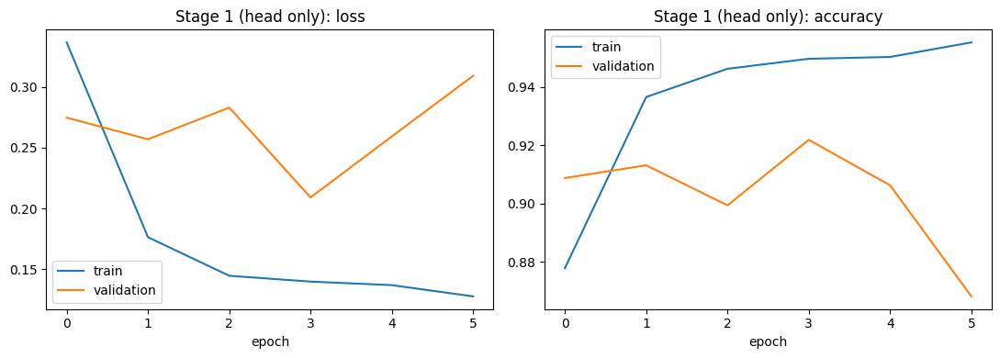

In [ ]:
# ===== Cell 5: Training functions + Stage 1 (train only the head) =====
import time

criterion = nn.CrossEntropyLoss()  # standard loss for multi-class classification

def run_epoch(model, loader, optimizer=None, keep_backbone_eval=False):
    """One pass over the data. If an optimizer is given -> training, otherwise -> evaluation."""
    training = optimizer is not None
    model.train() if training else model.eval()
    if training and keep_backbone_eval:
        # Frozen backbone: keep its BatchNorm layers in eval mode so ImageNet statistics don't drift
        model.features.eval()

    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):          # no gradients needed when evaluating
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)                 # forward pass: get class scores
            loss = criterion(outputs, labels)       # how wrong were we?

            if training:
                optimizer.zero_grad()               # clear old gradients
                loss.backward()                     # compute new gradients
                optimizer.step()                    # update the trainable weights

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            n += images.size(0)
    return total_loss / n, correct / n

def fit(model, optimizer, epochs, save_path, keep_backbone_eval=False):
    """Train for several epochs, track metrics, and save the best model (by validation accuracy)."""
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    for epoch in range(1, epochs + 1):
        start = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, keep_backbone_eval)
        va_loss, va_acc = run_epoch(model, val_loader)

        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)

        if va_acc > best_val_acc:                   # keep the best version of the model
            best_val_acc = va_acc
            torch.save(model.state_dict(), save_path)

        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-start:.0f}s")
    print(f"\nBest validation accuracy: {best_val_acc:.3f}")
    return history

def plot_history(history, title):
    """Plot loss and accuracy curves for train vs validation."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="validation")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

# --- Stage 1: only the parameters with requires_grad=True (the new head) get optimized ---
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-3
)

history1 = fit(model, optimizer, epochs=6, save_path="best_stage1.pth", keep_backbone_eval=True)
plot_history(history1, "Stage 1 (head only)")

              precision    recall  f1-score   support

       field      0.955     0.905     0.929       400
  vegetation      0.889     0.900     0.894       400
    building      0.969     0.945     0.957       400
        road      0.880     0.938     0.908       400

    accuracy                          0.922      1600
   macro avg      0.923     0.922     0.922      1600
weighted avg      0.923     0.922     0.922      1600



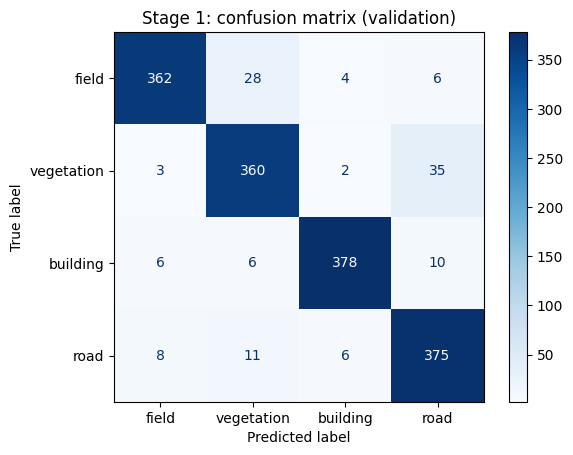


Total mistakes: 125 out of 1600


/tmp/ipykernel_2999/2335527892.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="upper left")


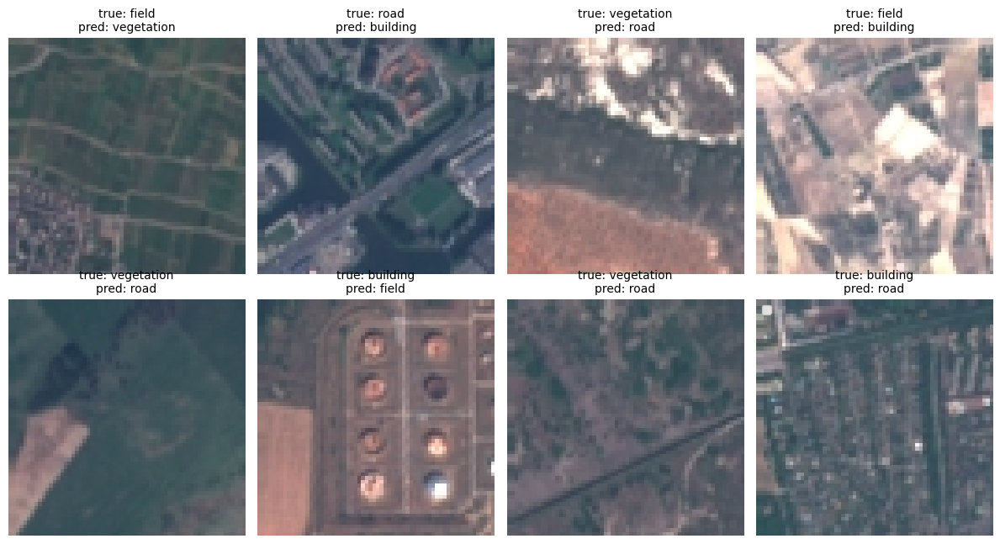

In [ ]:
# ===== Cell 6: Evaluate the best Stage 1 model =====

# Load the best weights saved during training (epoch 4), not the last epoch
model.load_state_dict(torch.load("best_stage1.pth", map_location=device))
model.eval()

def get_predictions(model, loader):
    """Run the model on a whole loader and return true labels and predicted labels."""
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_preds.extend(outputs.argmax(1).cpu().tolist())
            all_labels.extend(labels.tolist())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(model, val_loader)

# Precision / recall / F1 for each class, plus overall accuracy
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d")
plt.title("Stage 1: confusion matrix (validation)")
plt.show()

# Show 8 mistakes: val_loader is not shuffled, so position i matches val_items[i]
wrong = np.where(y_true != y_pred)[0]
print(f"\nTotal mistakes: {len(wrong)} out of {len(y_true)}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, i in zip(axes.flat, random.sample(list(wrong), min(8, len(wrong)))):
    img_idx, _ = val_items[i]
    ax.imshow(full[img_idx][0])
    ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

Trainable parameters: 3,800,788 of 4,207,156 (90.3%)
Epoch  1/8 | train loss 0.416 acc 0.853 | val loss 3.108 acc 0.342 | 67s
Epoch  2/8 | train loss 0.228 acc 0.914 | val loss 3.330 acc 0.261 | 67s
Epoch  3/8 | train loss 0.179 acc 0.934 | val loss 3.200 acc 0.269 | 67s
Epoch  4/8 | train loss 0.172 acc 0.939 | val loss 3.268 acc 0.272 | 66s
Epoch  5/8 | train loss 0.148 acc 0.943 | val loss 2.781 acc 0.282 | 66s
Epoch  6/8 | train loss 0.140 acc 0.953 | val loss 2.538 acc 0.286 | 66s
Epoch  7/8 | train loss 0.127 acc 0.955 | val loss 3.031 acc 0.281 | 66s
Epoch  8/8 | train loss 0.127 acc 0.955 | val loss 3.083 acc 0.274 | 65s

Best validation accuracy: 0.342


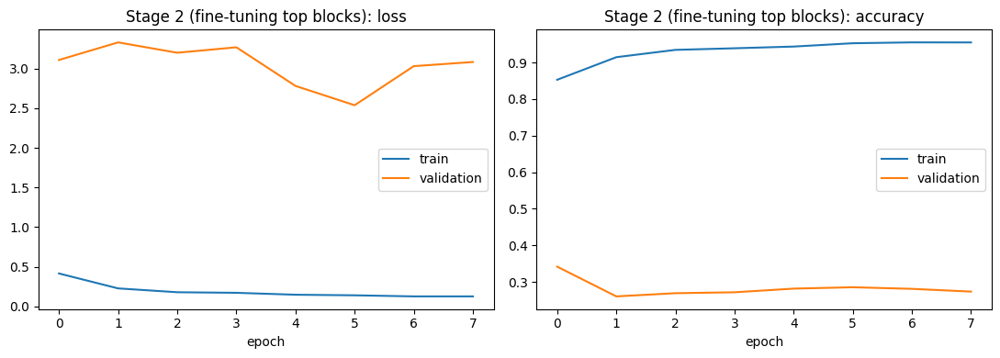

In [ ]:
# ===== Cell 7: Stage 2 - unfreeze the top backbone blocks and fine-tune gently =====

# Start from the best Stage 1 weights (already loaded in Cell 6, but we reload to be explicit)
model.load_state_dict(torch.load("best_stage1.pth", map_location=device))

# Unfreeze the LAST blocks of the backbone (features[12:]).
# Early blocks detect generic things (edges, textures) and don't need to change;
# late blocks are more specific and benefit from adapting to satellite images.
for param in model.features[12:].parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} of {total:,} ({100 * trainable / total:.1f}%)")

# Two learning rates: a tiny one for the pretrained backbone blocks (don't break them),
# and a larger one for the head (which is already trained but can still improve).
optimizer = torch.optim.Adam([
    {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": 1e-4},
    {"params": model.classifier.parameters(),                               "lr": 3e-4},
])

# keep_backbone_eval=False: now BatchNorm layers also adapt to the new image type
history2 = fit(model, optimizer, epochs=8, save_path="best_stage2.pth", keep_backbone_eval=False)
plot_history(history2, "Stage 2 (fine-tuning top blocks)")

Trainable parameters: 3,800,788 of 4,207,156 (90.3%)
Epoch  1/6 | train loss 0.147 acc 0.949 | val loss 0.186 acc 0.929 | 67s
Epoch  2/6 | train loss 0.105 acc 0.960 | val loss 0.093 acc 0.966 | 66s
Epoch  3/6 | train loss 0.093 acc 0.968 | val loss 0.145 acc 0.949 | 67s
Epoch  4/6 | train loss 0.081 acc 0.972 | val loss 0.111 acc 0.962 | 67s
Epoch  5/6 | train loss 0.063 acc 0.978 | val loss 0.088 acc 0.968 | 66s
Epoch  6/6 | train loss 0.057 acc 0.981 | val loss 0.100 acc 0.969 | 66s

Best validation accuracy: 0.969


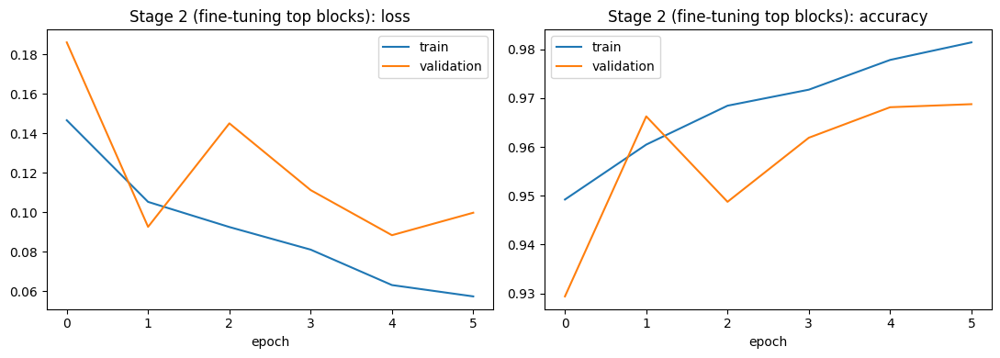

In [ ]:
# ===== Cell 7 (fixed): Stage 2 - fine-tune top blocks, keep BatchNorm statistics frozen =====

# Start again from the best Stage 1 weights (this throws away the broken Stage 2 model)
model.load_state_dict(torch.load("best_stage1.pth", map_location=device))

# Re-freeze everything in the backbone first, then unfreeze only the last blocks
for param in model.features.parameters():
    param.requires_grad = False
for param in model.features[12:].parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} of {total:,} ({100 * trainable / total:.1f}%)")

# Small learning rate for the pretrained blocks, larger for the head
optimizer = torch.optim.Adam([
    {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": 1e-4},
    {"params": model.classifier.parameters(),                               "lr": 3e-4},
])

# keep_backbone_eval=True: the backbone's BatchNorm layers stay in eval mode, so their
# running statistics don't drift toward our augmented images. The unfrozen weights still learn.
history2 = fit(model, optimizer, epochs=6, save_path="best_stage2.pth", keep_backbone_eval=True)
plot_history(history2, "Stage 2 (fine-tuning top blocks)")

Model                             Accuracy  Macro F1
Stage 1 (head only)                  0.922     0.922
Stage 2 (top blocks unfrozen)        0.969     0.969

Stage 2 per-class report:
              precision    recall  f1-score   support

       field      0.922     0.973     0.946       400
  vegetation      0.978     0.910     0.943       400
    building      0.995     1.000     0.998       400
        road      0.983     0.993     0.988       400

    accuracy                          0.969      1600
   macro avg      0.969     0.969     0.969      1600
weighted avg      0.969     0.969     0.969      1600



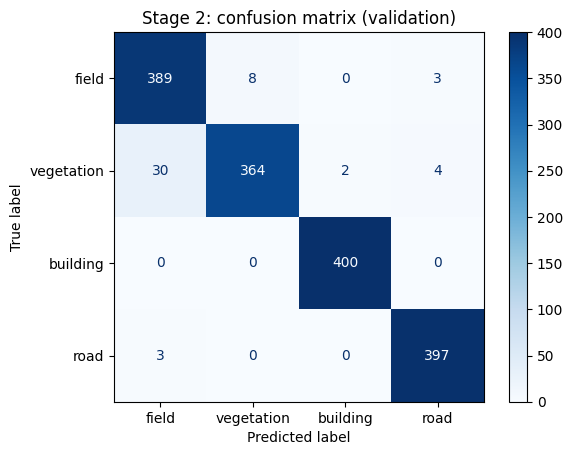

In [ ]:
# ===== Cell 8: Compare Stage 1 vs Stage 2 on the validation set =====
from sklearn.metrics import accuracy_score, f1_score

def load_model(weights_path):
    """Build a fresh MobileNetV3 with our 4-class head and load saved weights into it."""
    m = models.mobilenet_v3_large(weights=None)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
    m.load_state_dict(torch.load(weights_path, map_location=device))
    return m.to(device).eval()

results = {}
for name, path in [("Stage 1 (head only)", "best_stage1.pth"),
                   ("Stage 2 (top blocks unfrozen)", "best_stage2.pth")]:
    m = load_model(path)
    y_true, y_pred = get_predictions(m, val_loader)
    results[name] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_pred": y_pred,
    }

# Results table
print(f"{'Model':<32}{'Accuracy':>10}{'Macro F1':>10}")
for name, r in results.items():
    print(f"{name:<32}{r['accuracy']:>10.3f}{r['macro_f1']:>10.3f}")

# Per-class report and confusion matrix for Stage 2
y_pred2 = results["Stage 2 (top blocks unfrozen)"]["y_pred"]
print("\nStage 2 per-class report:")
print(classification_report(y_true, y_pred2, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred2)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d")
plt.title("Stage 2: confusion matrix (validation)")
plt.show()

# Use Stage 2 as our main model from here on
model = load_model("best_stage2.pth")

Saving cansat8.jpg to cansat8.jpg
Saving cansat7.jpg to cansat7.jpg
Saving cansat6.jpg to cansat6.jpg
Saving cansat5.jpg to cansat5.jpg
Saving cansat4.jpg to cansat4.jpg
Saving cansat 3.jpg to cansat 3.jpg
Saving cansat2.jpg to cansat2.jpg
Saving cansat1.jpg to cansat1.jpg
Uploaded: ['cansat 3.jpg', 'cansat1.jpg', 'cansat2.jpg', 'cansat4.jpg', 'cansat5.jpg', 'cansat6.jpg', 'cansat7.jpg', 'cansat8.jpg']


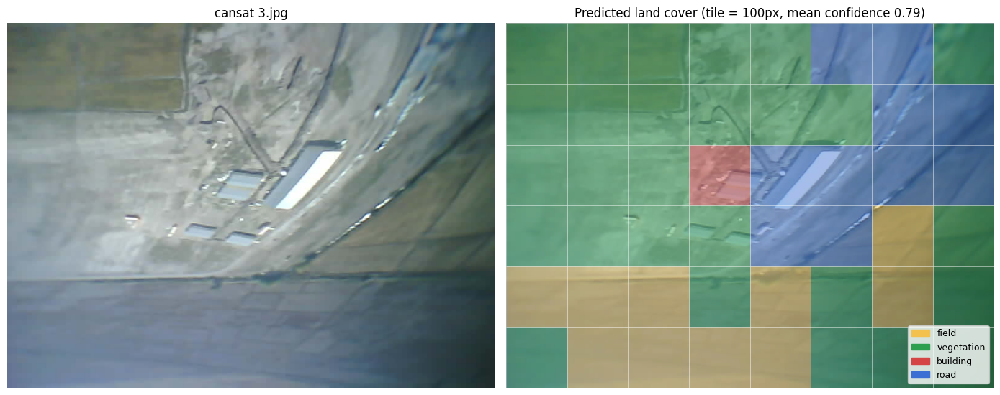

cansat 3.jpg -> {'field': 10, 'vegetation': 27, 'building': 1, 'road': 10} 



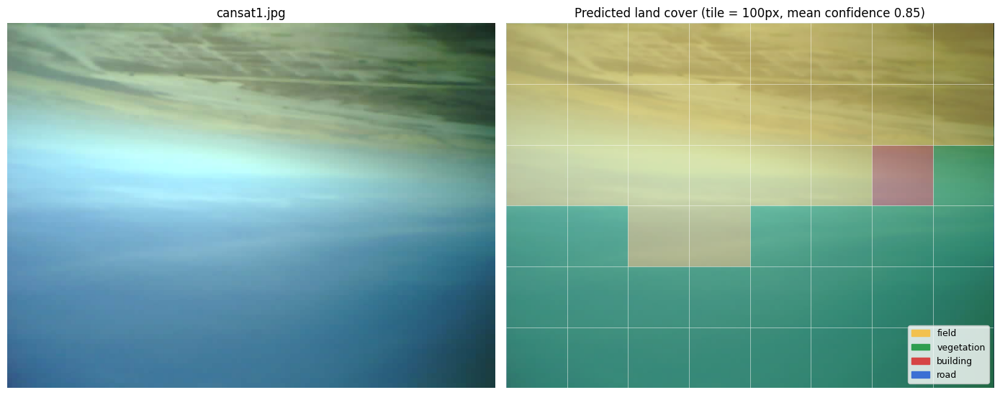

cansat1.jpg -> {'field': 24, 'vegetation': 23, 'building': 1, 'road': 0} 



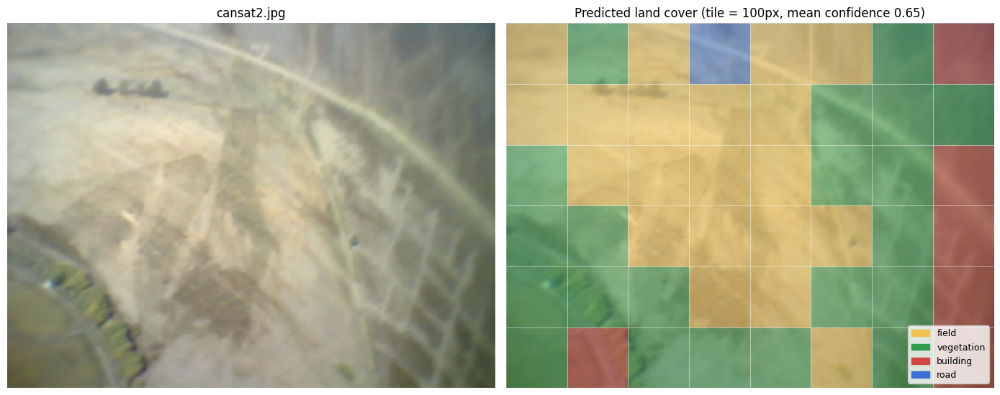

cansat2.jpg -> {'field': 20, 'vegetation': 21, 'building': 6, 'road': 1} 



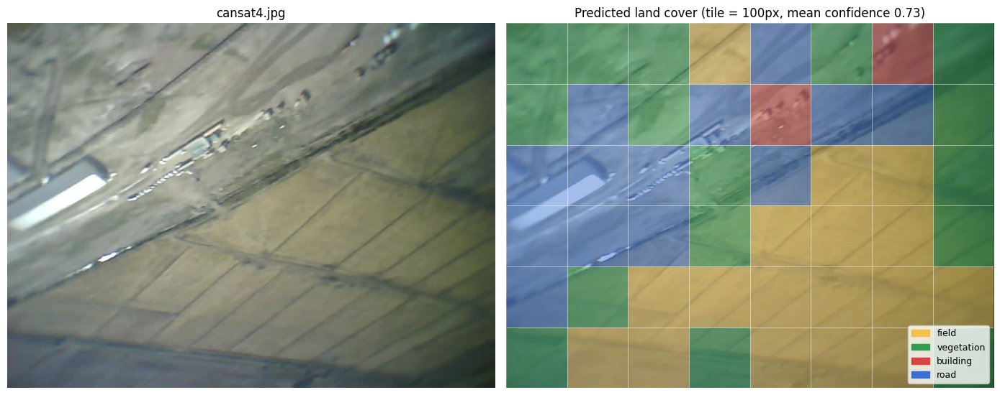

cansat4.jpg -> {'field': 17, 'vegetation': 16, 'building': 2, 'road': 13} 



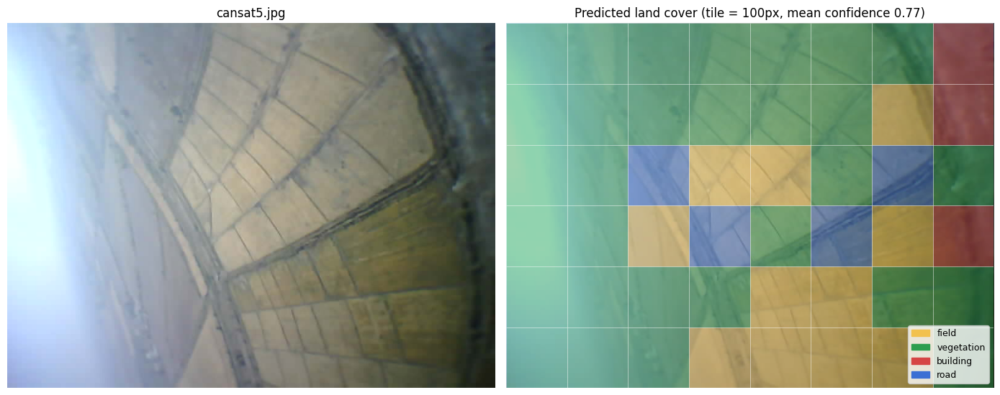

cansat5.jpg -> {'field': 11, 'vegetation': 30, 'building': 3, 'road': 4} 



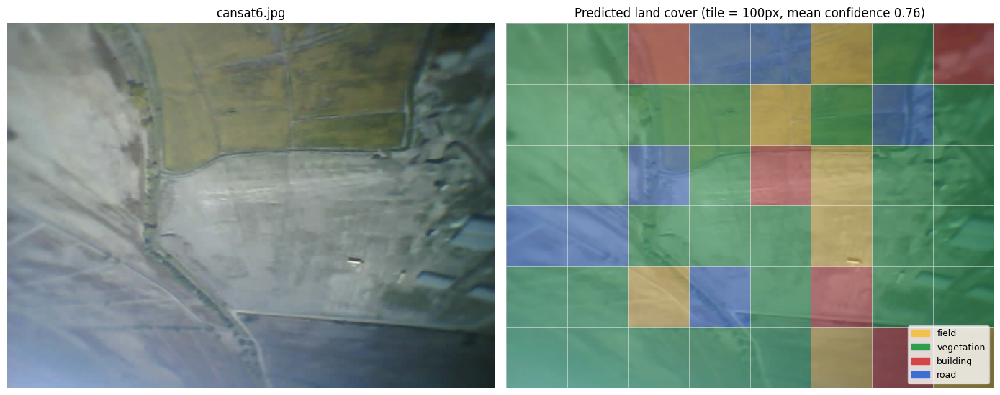

cansat6.jpg -> {'field': 7, 'vegetation': 29, 'building': 5, 'road': 7} 



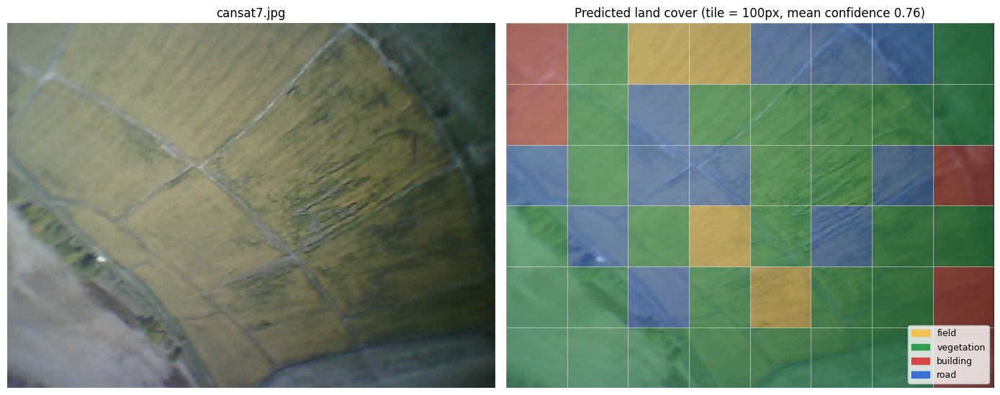

cansat7.jpg -> {'field': 4, 'vegetation': 28, 'building': 5, 'road': 11} 



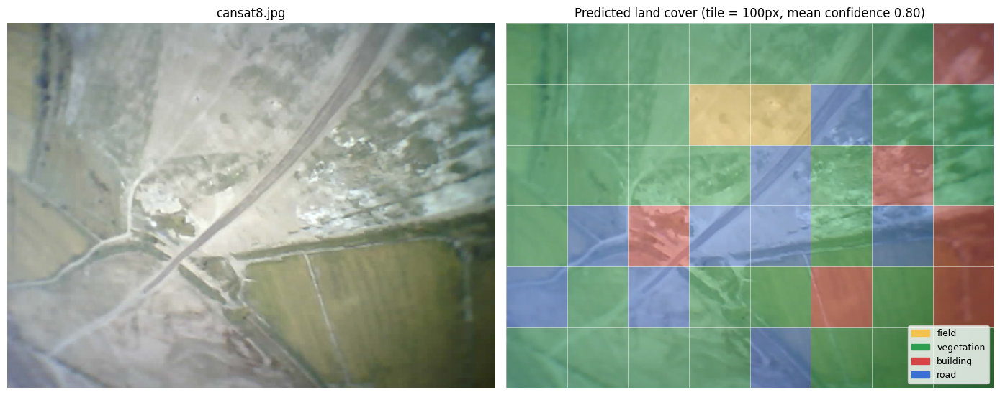

cansat8.jpg -> {'field': 2, 'vegetation': 31, 'building': 6, 'road': 9} 



In [ ]:
# ===== Cell 9: Test on CanSat photos + land-cover map =====
import os
from google.colab import files
from matplotlib.patches import Rectangle, Patch

# 1) Upload your CanSat photos (select all of them at once in the file dialog)
uploaded = files.upload()
photo_names = sorted(uploaded.keys())
print("Uploaded:", photo_names)

# 2) Settings: tile size in pixels (photos are ~800x600, so 100 px gives 8x6 = 48 tiles).
#    Try 100 first, then maybe 150 or 200 and see which map looks best.
TILE = 100

# One color per class for the map
class_colors = {"field": "#f2c14e", "vegetation": "#2e9e4f", "building": "#d64545", "road": "#3b6fd4"}

os.makedirs("maps", exist_ok=True)
model.eval()

def predict_tiles(img, tile=TILE):
    """Cut a PIL image into non-overlapping tiles and predict a class for each one."""
    W, H = img.size
    boxes, batch = [], []
    for y in range(0, H - tile + 1, tile):
        for x in range(0, W - tile + 1, tile):
            crop = img.crop((x, y, x + tile, y + tile))
            batch.append(val_tf(crop))          # same preprocessing as validation (no augmentation)
            boxes.append((x, y))
    batch = torch.stack(batch).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(batch), dim=1)   # turn scores into probabilities
    conf, pred = probs.max(dim=1)                    # best class + how sure the model is
    return boxes, pred.cpu().numpy(), conf.cpu().numpy()

def show_map(name, alpha=0.45):
    """Show the original photo next to the same photo painted with predicted classes."""
    img = Image.open(name).convert("RGB")
    boxes, pred, conf = predict_tiles(img)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    ax[0].imshow(img); ax[0].set_title(name); ax[0].axis("off")
    ax[1].imshow(img)
    for (x, y), p in zip(boxes, pred):
        ax[1].add_patch(Rectangle((x, y), TILE, TILE, facecolor=class_colors[class_names[p]],
                                  edgecolor="white", linewidth=0.5, alpha=alpha))
    ax[1].set_title(f"Predicted land cover (tile = {TILE}px, mean confidence {conf.mean():.2f})")
    ax[1].axis("off")
    ax[1].legend(handles=[Patch(color=c, label=n) for n, c in class_colors.items()],
                 loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"maps/{os.path.splitext(name)[0]}_map.png", dpi=150)   # saved for the README
    plt.show()

    # How many tiles went to each class
    counts = {class_names[c]: int((pred == c).sum()) for c in range(len(class_names))}
    print(name, "->", counts, "\n")

# 3) Run on every uploaded photo
for name in photo_names:
    show_map(name)

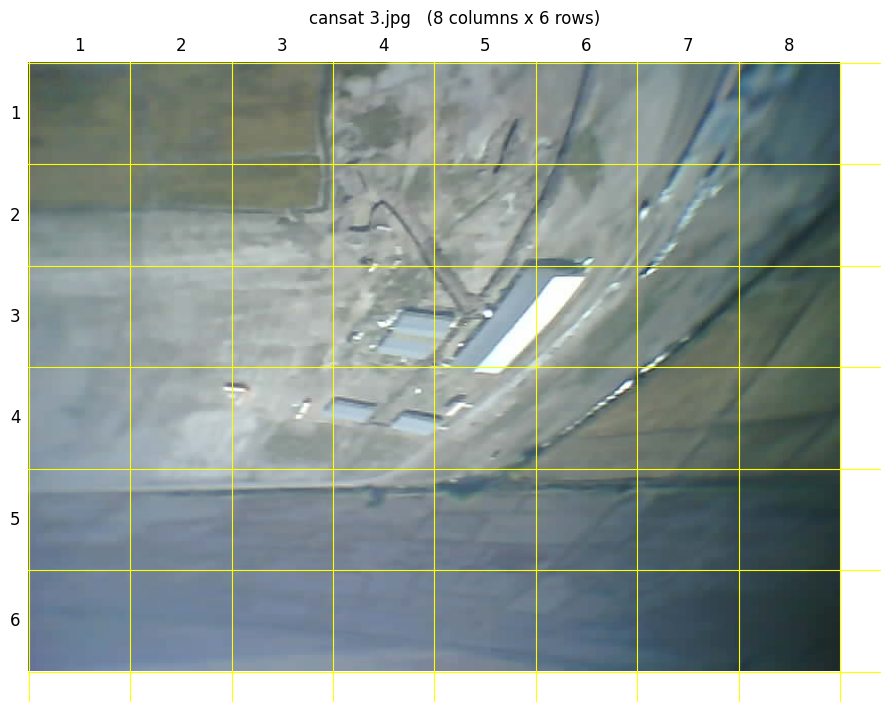

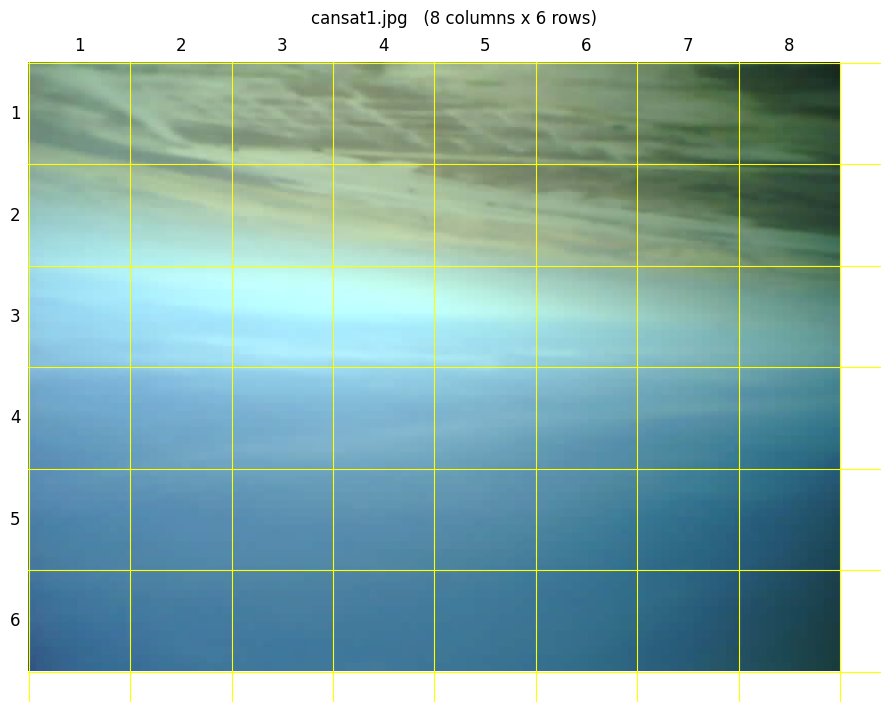

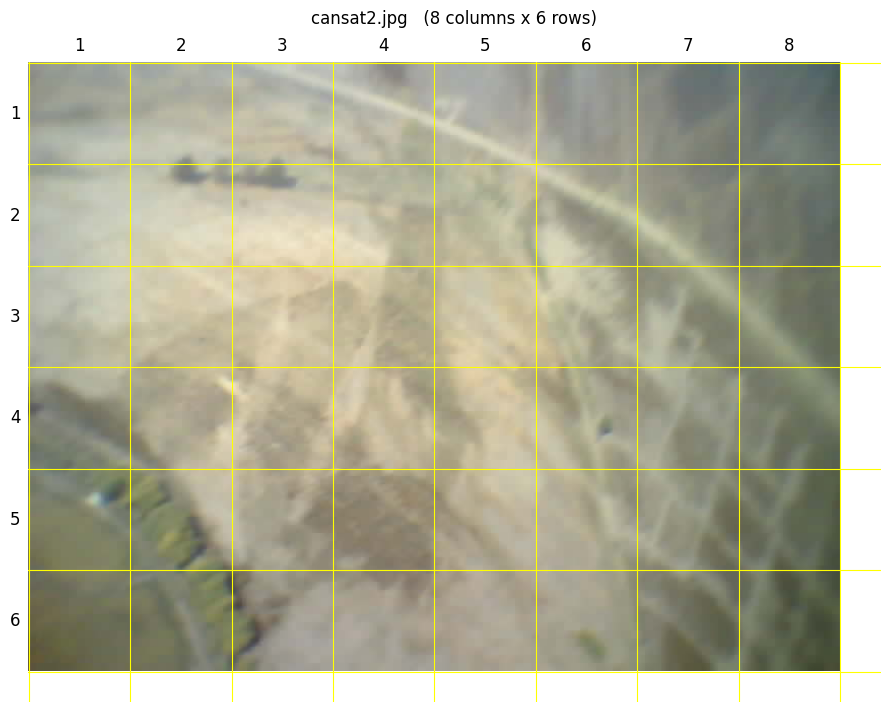

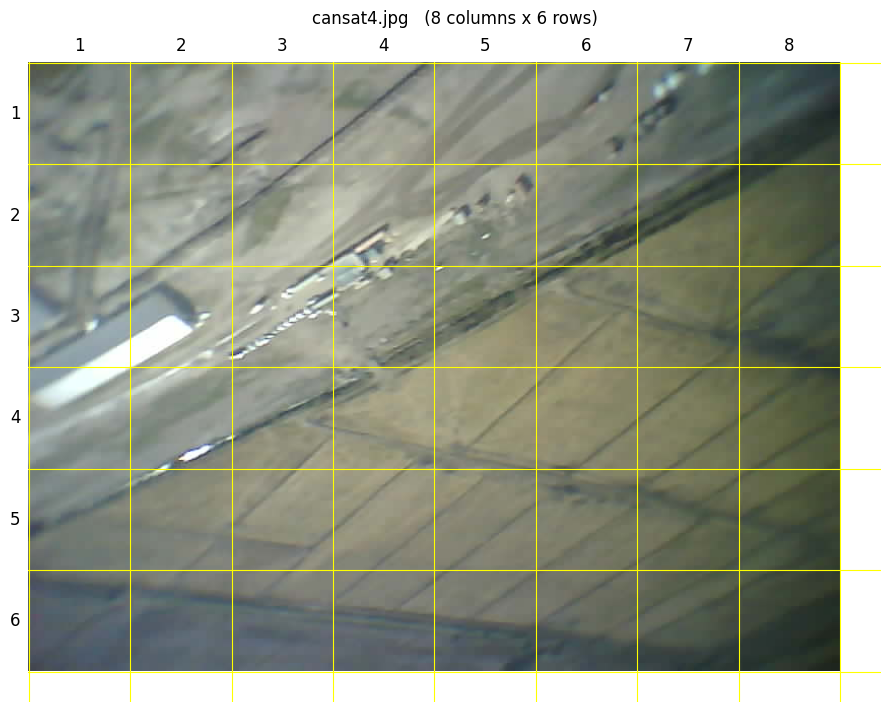

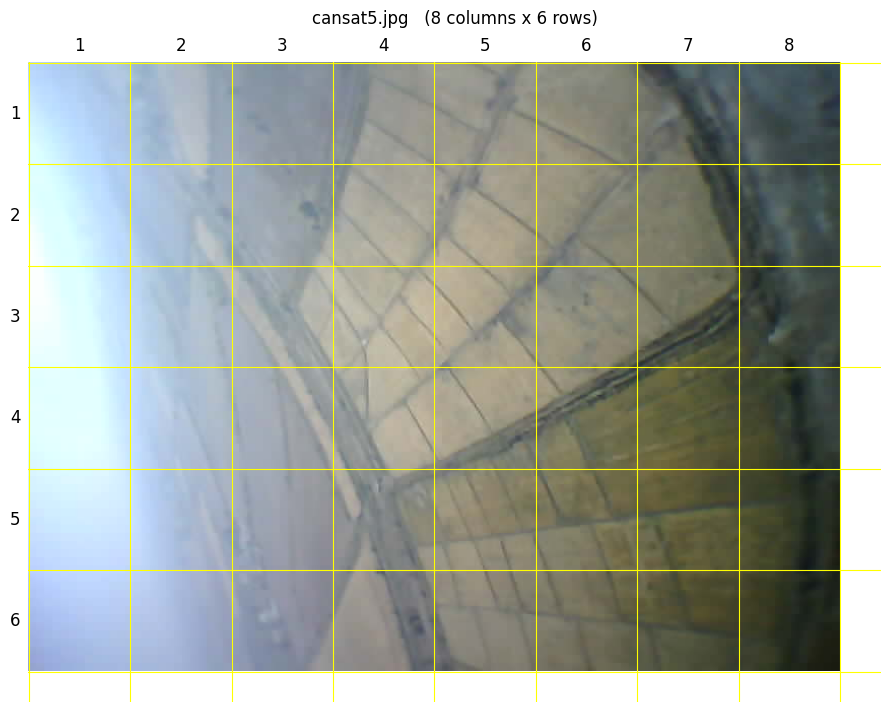

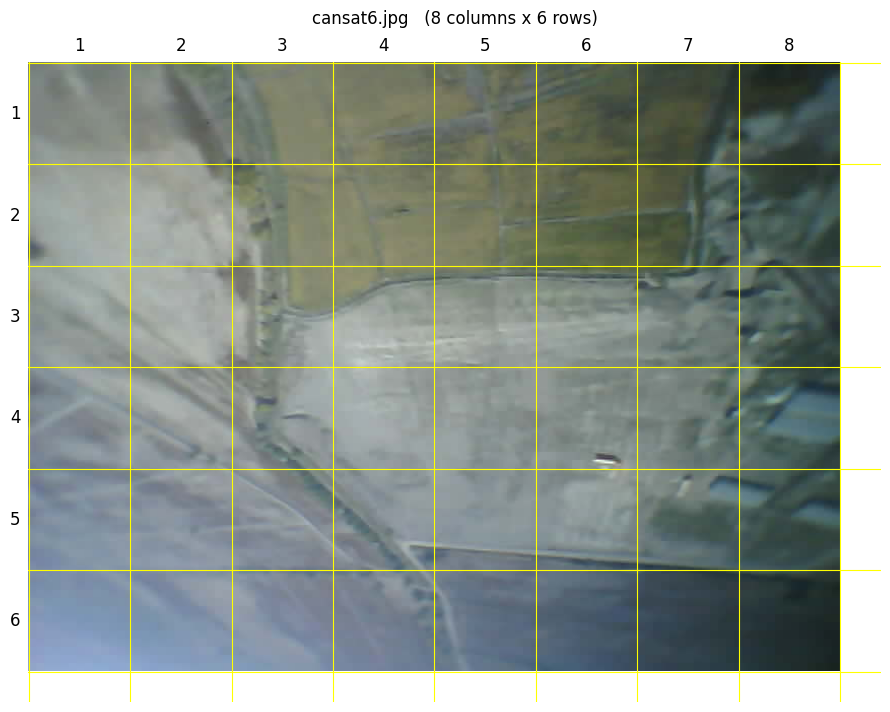

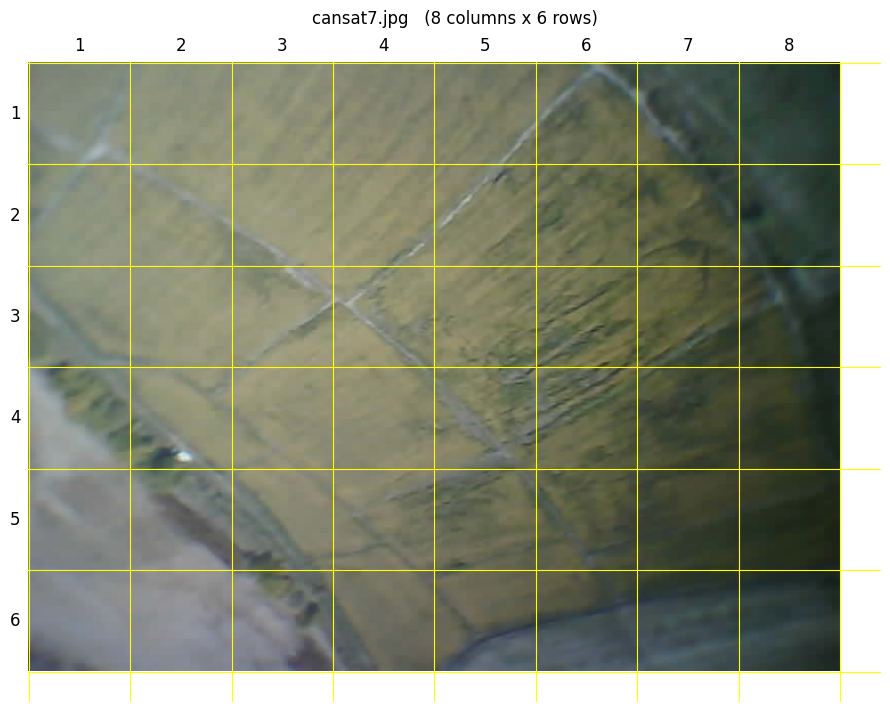

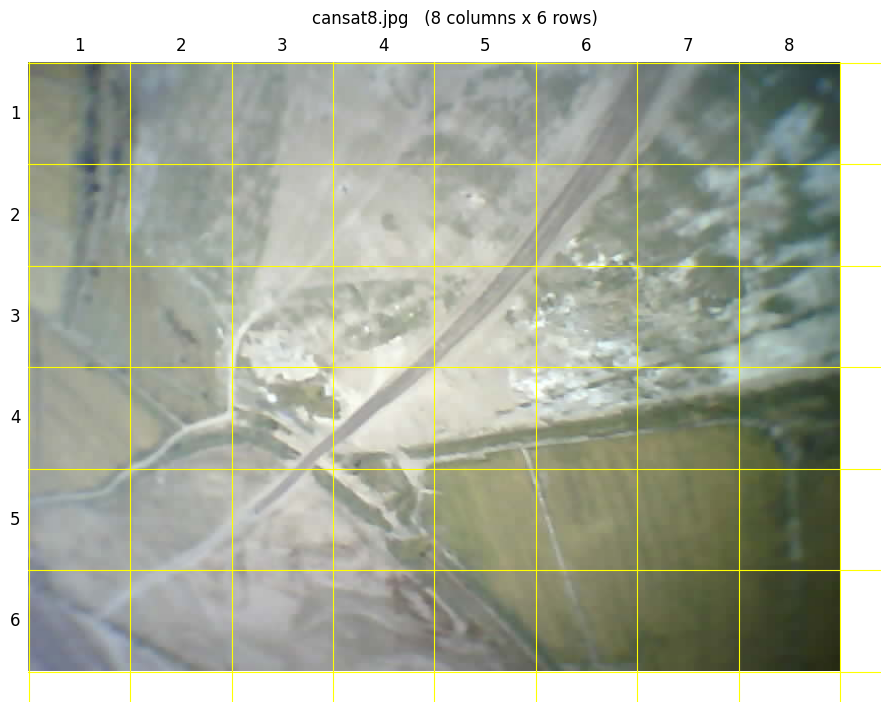

In [ ]:
# ===== Cell 10: Show each photo with a numbered tile grid (for labeling) =====
TILE = 100   # same tile size as in the maps

def show_grid(name):
    img = Image.open(name).convert("RGB")
    W, H = img.size
    cols, rows = W // TILE, H // TILE
    fig, ax = plt.subplots(figsize=(11, 8.5))
    ax.imshow(img)
    # Draw the grid lines
    for c in range(cols + 1):
        ax.axvline(c * TILE, color="yellow", lw=0.8)
    for r in range(rows + 1):
        ax.axhline(r * TILE, color="yellow", lw=0.8)
    # Row numbers on the left, column numbers on top
    for r in range(rows):
        ax.text(-8, r * TILE + TILE / 2, str(r + 1), ha="right", va="center", fontsize=12)
    for c in range(cols):
        ax.text(c * TILE + TILE / 2, -8, str(c + 1), ha="center", va="bottom", fontsize=12)
    ax.set_title(f"{name}   ({cols} columns x {rows} rows)", pad=28)
    ax.axis("off")
    plt.show()

for name in photo_names:
    show_grid(name)

In [ ]:
LABELS = {

     "cansat 3.jpg": [
        "fffdddxx",   # row 1
        "xxxddxxx",   # row 2
        "dddbbxff",   # row 3
        "dddxxxff",   # row 4
        "ffffffvv",   # row 5
        "ffffffvv",   # row 6
    ],
    "cansat1.jpg": [
        "ffffffxx",   # row 1
        "ssffffxx",   # row 2
        "ssssssss",   # row 3
        "ssssssss",   # row 4
        "ssssssss",   # row 5
        "ssssssss",   # row 6
    ],
    "cansat2.jpg": [
        "dddddxxx",   # row 1
        "dxxddxxx",   # row 2
        "dddddxxx",   # row 3
        "xddddxxx",   # row 4
        "xvxddxxx",   # row 5
        "fxxddxxx",   # row 6
    ],
    "cansat4.jpg": [
        "dddddxxx",   # row 1
        "ddddxxxx",   # row 2
        "bbxxxxxx",   # row 3
        "xxxxfffx",   # row 4
        "xffffffx",   # row 5
        "xxxxxxxx",   # row 6
    ],
    "cansat5.jpg": [
        "sxdfffxx",   # row 1
        "sxdffffx",   # row 2
        "sxxffffx",   # row 3
        "xxxxxffx",   # row 4
        "xxxxfffx",   # row 5
        "xxxxfffx",   # row 6
    ],
    "cansat6.jpg": [
        "ddxffffx",   # row 1
        "ddxffffx",   # row 2
        "ddxddddx",   # row 3
        "ddxddddb",   # row 4
        "xxxddddb",   # row 5
        "xxxxxxxx",   # row 6
    ],
    "cansat7.jpg": [
        "xffffxxx",   # row 1
        "fffffffx",   # row 2
        "fffffffx",   # row 3
        "xffffffx",   # row 4
        "ddxffffx",   # row 5
        "dddxxxxx",   # row 6
    ],
    "cansat8.jpg": [
        "fddddrxd",   # row 1
        "fdddxrdd",   # row 2
        "xdddrddd",   # row 3
        "fxxrxxff",   # row 4
        "dxrxffff",   # row 5
        "xxddxfff",   # row 6
    ],
}

In [ ]:
# ===== Cell 12: Check labels, count tiles per class, cut tiles into folders =====
import pandas as pd

# Letter -> class name. 'x' means "skipped" and is ignored.
LETTER_TO_CLASS = {"f": "field", "v": "vegetation", "b": "building",
                   "r": "road",  "d": "bare_land",  "s": "sky"}
ROWS, COLS, TILE = 6, 8, 100

records, problems = [], []

# 1) Read and validate every label
for name in photo_names:
    if name not in LABELS:
        problems.append(f"{name}: no labels found (check the file name in LABELS)")
        continue
    rows = LABELS[name]
    if len(rows) != ROWS:
        problems.append(f"{name}: has {len(rows)} rows, needs {ROWS}")
    for r, row in enumerate(rows):
        if len(row) != COLS:
            problems.append(f"{name} row {r + 1}: has {len(row)} letters, needs {COLS}")
        for c, ch in enumerate(row):
            if ch == "x":
                continue
            if ch not in LETTER_TO_CLASS:
                problems.append(f"{name} row {r + 1}, column {c + 1}: unknown letter '{ch}'")
                continue
            records.append({"photo": name, "row": r, "col": c, "label": LETTER_TO_CLASS[ch]})

if problems:
    print("Please fix these first, then run this cell again:")
    for p in problems:
        print(" -", p)
else:
    df = pd.DataFrame(records)

    # 2) How many labeled tiles does each photo give us, per class?
    table = pd.crosstab(df["photo"], df["label"])
    table["total"] = table.sum(axis=1)
    print("Labeled tiles per photo and class:")
    display(table)
    print("\nTotal per class:")
    print(df["label"].value_counts().to_string())

    # 3) Cut the tiles and save them as images: tiles/<photo>/<class>/r<row>_c<col>.png
    for name in df["photo"].unique():
        img = Image.open(name).convert("RGB")
        if img.size != (COLS * TILE, ROWS * TILE):
            print(f"Note: {name} is {img.size}, expected {(COLS * TILE, ROWS * TILE)}")
        stem = os.path.splitext(name)[0].replace(" ", "_")
        for _, t in df[df["photo"] == name].iterrows():
            x, y = int(t["col"]) * TILE, int(t["row"]) * TILE
            folder = f"tiles/{stem}/{t['label']}"
            os.makedirs(folder, exist_ok=True)
            img.crop((x, y, x + TILE, y + TILE)).save(f"{folder}/r{int(t['row'])+1}_c{int(t['col'])+1}.png")

    # 4) Save the label table
    df.to_csv("tile_labels.csv", index=False)
    print(f"\nSaved {len(df)} tiles into the 'tiles/' folder and tile_labels.csv")

Labeled tiles per photo and class:


label,bare_land,building,field,road,sky,vegetation,total
photo,,,,,,,
cansat 3.jpg,11,2,19,0,0,4,36
cansat1.jpg,0,0,10,0,34,0,44
cansat2.jpg,21,0,1,0,0,1,23
cansat4.jpg,9,2,9,0,0,0,20
cansat5.jpg,2,0,19,0,3,0,24
cansat6.jpg,20,2,8,0,0,0,30
cansat7.jpg,5,0,28,0,0,0,33
cansat8.jpg,19,0,12,5,0,0,36



Total per class:
label
field         106
bare_land      87
sky            37
building        6
vegetation      5
road            5

Saved 246 tiles into the 'tiles/' folder and tile_labels.csv


In [ ]:
# ===== Cell 13: Retrain with 6 classes (EuroSAT + our own CanSat tiles) =====

# 1) Which photos stay hidden for the final test? (never used in training)
HOLDOUT = ["cansat4.jpg", "cansat8.jpg"]

CLASSES6 = ["field", "vegetation", "building", "road", "bare_land", "sky"]   # first 4 = same order as before
label_to_idx = {c: i for i, c in enumerate(CLASSES6)}

# 2) Cut our labeled tiles out of the photos (in memory)
df = pd.read_csv("tile_labels.csv")

def crop_tiles(frame):
    photos, out = {}, []
    for _, t in frame.iterrows():
        if t["photo"] not in photos:
            photos[t["photo"]] = Image.open(t["photo"]).convert("RGB")
        x, y = int(t["col"]) * TILE, int(t["row"]) * TILE
        out.append((photos[t["photo"]].crop((x, y, x + TILE, y + TILE)), label_to_idx[t["label"]]))
    return out

own_train = crop_tiles(df[~df["photo"].isin(HOLDOUT)])
print("Own training tiles per class:", {CLASSES6[i]: sum(1 for _, l in own_train if l == i) for i in range(6)})
print("Hidden test tiles:", int(df["photo"].isin(HOLDOUT).sum()))

# 3) A smaller EuroSAT subset (1000 per class) to keep training fast
eurosat_small = []
for lab in range(4):
    idxs = [i for i, l in train_items if l == lab][:1000]
    eurosat_small += [(i, lab) for i in idxs]

# 4) Dataset that mixes EuroSAT tiles and our own tiles (own tiles repeated 4x: there are few)
class MixedDataset(torch.utils.data.Dataset):
    def __init__(self, euro_items, own_items, transform, own_repeat=4):
        self.euro, self.own, self.transform = euro_items, own_items * own_repeat, transform
    def __len__(self):
        return len(self.euro) + len(self.own)
    def __getitem__(self, i):
        if i < len(self.euro):
            idx, label = self.euro[i]
            img = full[idx][0].convert("RGB")
        else:
            img, label = self.own[i - len(self.euro)]
        return self.transform(img), label

mixed_loader = DataLoader(MixedDataset(eurosat_small, own_train, train_tf),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

# 5) New model: start from the Stage 2 weights, swap the head to 6 outputs
model6 = load_model("best_stage2.pth")
old_head = model6.classifier[3]
new_head = nn.Linear(old_head.in_features, len(CLASSES6))
with torch.no_grad():                         # keep what the model already knows about the first 4 classes
    new_head.weight[:4] = old_head.weight
    new_head.bias[:4] = old_head.bias
model6.classifier[3] = new_head
model6 = model6.to(device)

# 6) Same recipe as Stage 2: top backbone blocks + head are trainable, BatchNorm stats stay frozen
for p in model6.features.parameters():
    p.requires_grad = False
for p in model6.features[12:].parameters():
    p.requires_grad = True
optimizer = torch.optim.Adam([
    {"params": [p for p in model6.features.parameters() if p.requires_grad], "lr": 1e-4},
    {"params": model6.classifier.parameters(), "lr": 3e-4},
])

# 7) Train a FIXED number of epochs and keep the last model (no picking the best epoch on the test photos)
EPOCHS = 5
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    tr_loss, tr_acc = run_epoch(model6, mixed_loader, optimizer, keep_backbone_eval=True)
    _, eu_acc = run_epoch(model6, val_loader)    # sanity check: EuroSAT validation (4 old classes)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"EuroSAT val acc {eu_acc:.3f} | {time.time() - start:.0f}s")

torch.save(model6.state_dict(), "model_6class.pth")
print("Saved model_6class.pth")

Own training tiles per class: {'field': 85, 'vegetation': 5, 'building': 4, 'road': 0, 'bare_land': 59, 'sky': 37}
Hidden test tiles: 56
Epoch 1/5 | train loss 0.183 acc 0.938 | EuroSAT val acc 0.974 | 49s
Epoch 2/5 | train loss 0.111 acc 0.961 | EuroSAT val acc 0.969 | 50s
Epoch 3/5 | train loss 0.085 acc 0.972 | EuroSAT val acc 0.962 | 48s
Epoch 4/5 | train loss 0.066 acc 0.977 | EuroSAT val acc 0.968 | 50s
Epoch 5/5 | train loss 0.066 acc 0.976 | EuroSAT val acc 0.968 | 50s
Saved model_6class.pth


Hidden test tiles: 56

class        tiles     BEFORE     AFTER
field           21       8/21      17/21 
building         2       0/2        2/2  
road             5       4/5        1/5  
bare_land       28       0/28      22/28 

Always-guess-the-most-common-class baseline: 0.500
BEFORE  accuracy 0.214 | macro F1 0.254 | accuracy on tiles of the 4 old classes 0.429
AFTER   accuracy 0.750 | macro F1 0.605 | accuracy on tiles of the 4 old classes 0.714


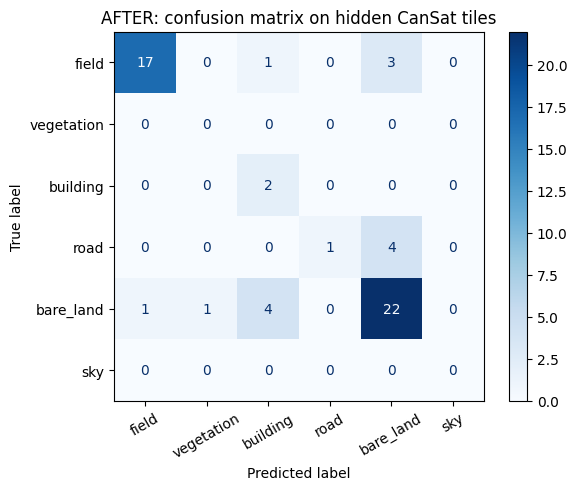

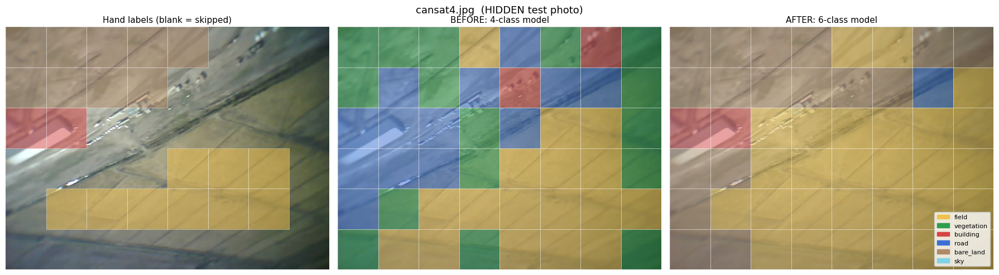

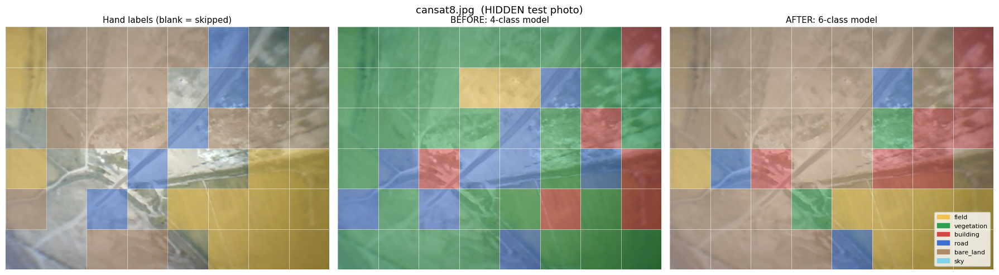

In [ ]:
# ===== Cell 14: Before vs After on the hidden test photos =====
from sklearn.metrics import f1_score

# 1) The two models to compare
model_before = load_model("best_stage2.pth")     # 4 outputs: field, vegetation, building, road
model_after  = model6.eval()                     # 6 outputs: + bare_land, sky

# 2) Hidden test tiles with our hand-made labels
test_df = df[df["photo"].isin(HOLDOUT)].reset_index(drop=True)
test_tiles = crop_tiles(test_df)                 # list of (PIL tile, label index)
y_true = np.array([lab for _, lab in test_tiles])

def predict_pil_tiles(m, tiles):
    """Predict a class index for a list of PIL tiles (same preprocessing as validation)."""
    preds = []
    with torch.no_grad():
        for i in range(0, len(tiles), 64):
            batch = torch.stack([val_tf(t) for t in tiles[i:i + 64]]).to(device)
            preds += m(batch).argmax(1).cpu().tolist()
    return np.array(preds)

imgs = [t for t, _ in test_tiles]
pred_before = predict_pil_tiles(model_before, imgs)
pred_after  = predict_pil_tiles(model_after,  imgs)

# 3) Per-class results: how many tiles of each class were found
print(f"Hidden test tiles: {len(y_true)}\n")
print(f"{'class':<12}{'tiles':>6}{'BEFORE':>11}{'AFTER':>10}")
for i, c in enumerate(CLASSES6):
    n = int((y_true == i).sum())
    if n == 0:
        continue
    b = int(((y_true == i) & (pred_before == i)).sum())
    a = int(((y_true == i) & (pred_after == i)).sum())
    print(f"{c:<12}{n:>6}{b:>8}/{n:<3}{a:>7}/{n:<3}")

# 4) Overall numbers
present = sorted(set(y_true))                     # only classes that exist in the hidden photos
known = y_true < 4                                # tiles whose class the OLD model could actually predict
print(f"\nAlways-guess-the-most-common-class baseline: {np.bincount(y_true).max() / len(y_true):.3f}")
for name, pred in [("BEFORE", pred_before), ("AFTER", pred_after)]:
    acc = (pred == y_true).mean()
    f1 = f1_score(y_true, pred, labels=present, average="macro", zero_division=0)
    acc_known = (pred[known] == y_true[known]).mean()
    print(f"{name:<7} accuracy {acc:.3f} | macro F1 {f1:.3f} | accuracy on tiles of the 4 old classes {acc_known:.3f}")

# 5) Confusion matrix of the new model (rows = hand label, columns = prediction)
cm = confusion_matrix(y_true, pred_after, labels=list(range(6)))
ConfusionMatrixDisplay(cm, display_labels=CLASSES6).plot(cmap="Blues", values_format="d", xticks_rotation=30)
plt.title("AFTER: confusion matrix on hidden CanSat tiles")
plt.show()

# 6) Maps: hand labels | before | after, saved for the README
colors6 = {"field": "#f2c14e", "vegetation": "#2e9e4f", "building": "#d64545",
           "road": "#3b6fd4", "bare_land": "#b08968", "sky": "#7fd3e8"}

def predict_grid(m, img):
    tiles = [img.crop((c * TILE, r * TILE, (c + 1) * TILE, (r + 1) * TILE))
             for r in range(ROWS) for c in range(COLS)]
    return predict_pil_tiles(m, tiles).reshape(ROWS, COLS)

def paint(ax, img, grid, title):
    ax.imshow(img); ax.set_title(title, fontsize=11); ax.axis("off")
    for r in range(ROWS):
        for c in range(COLS):
            if grid[r, c] >= 0:                   # -1 means "skipped tile": no colour
                ax.add_patch(Rectangle((c * TILE, r * TILE), TILE, TILE,
                                       facecolor=colors6[CLASSES6[grid[r, c]]],
                                       edgecolor="white", linewidth=0.5, alpha=0.5))

os.makedirs("maps_after", exist_ok=True)
for name in photo_names:
    img = Image.open(name).convert("RGB")
    truth = np.full((ROWS, COLS), -1)
    for _, t in df[df["photo"] == name].iterrows():
        truth[int(t["row"]), int(t["col"])] = label_to_idx[t["label"]]

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    paint(ax[0], img, truth, "Hand labels (blank = skipped)")
    paint(ax[1], img, predict_grid(model_before, img), "BEFORE: 4-class model")
    paint(ax[2], img, predict_grid(model_after,  img), "AFTER: 6-class model")
    ax[2].legend(handles=[Patch(color=c, label=n) for n, c in colors6.items()], loc="lower right", fontsize=8)
    hidden = name in HOLDOUT
    fig.suptitle(f"{name}  ({'HIDDEN test photo' if hidden else 'seen in training'})", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"maps_after/{os.path.splitext(name)[0]}_before_after.png", dpi=120)
    plt.show() if hidden else plt.close()

In [17]:
# ===== Cell 15: Pack everything for GitHub and download it =====
import shutil, json

# Save class names and settings next to the model (the demo app will need them)
config = {"classes": CLASSES6, "tile_px": TILE, "grid_rows": ROWS, "grid_cols": COLS,
          "input_size": IMG_SIZE, "holdout_photos": HOLDOUT, "backbone": "mobilenet_v3_large"}
json.dump(config, open("config.json", "w"), indent=2)

# Build the export folder
os.makedirs("export/results", exist_ok=True)
shutil.copy("model_6class.pth", "export/")
shutil.copy("best_stage2.pth", "export/model_4class_eurosat.pth")
shutil.copy("tile_labels.csv", "export/")
shutil.copy("config.json", "export/")
shutil.copytree("tiles", "export/tiles", dirs_exist_ok=True)
shutil.copytree("maps_after", "export/results/maps_after", dirs_exist_ok=True)
shutil.copytree("maps", "export/results/maps_first_try", dirs_exist_ok=True)

# Original photos (only publish these if your team agrees); spaces removed from file names
os.makedirs("export/photos", exist_ok=True)
for n in photo_names:
    shutil.copy(n, "export/photos/" + n.replace(" ", "_"))

shutil.make_archive("cansat_landcover_export", "zip", "export")
files.download("cansat_landcover_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>